# JobGuard 01: Cleaning and EDA
EMSCAD dataset (University of the Aegean): 17,880 job ads, 866 fraudulent.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from features import build_features
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
def save(name): plt.savefig(FIG + name, dpi=150, bbox_inches="tight"); plt.show()
raw = pd.read_csv("../data/fake_job_postings.csv")
print(raw.shape)
raw.head(3)

(17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


## Data understanding
Missing values per column (%) and class balance.

In [2]:
(raw.isna().mean().mul(100).round(1).sort_values(ascending=False).head(11)).to_frame("% missing")

,% missing
salary_range,84.0
department,64.6
required_education,45.3
benefits,40.3
required_experience,39.4
function,36.1
industry,27.4
employment_type,19.4
company_profile,18.5
requirements,15.1


fraudulent
0    17014
1      866
Name: count, dtype: int64
fraud rate: 4.84 %


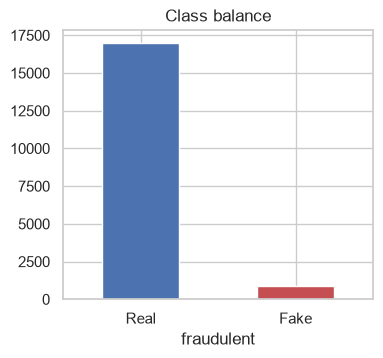

In [3]:
print(raw.fraudulent.value_counts()); print("fraud rate:", round(raw.fraudulent.mean()*100,2), "%")
fig, ax = plt.subplots(figsize=(4,3.5))
raw.fraudulent.map({0:"Real",1:"Fake"}).value_counts().plot.bar(ax=ax, color=["#4C72B0","#C44E52"], rot=0)
ax.set_title("Class balance"); save("01_class_balance.png")

**Finding:** only ~4.8% of ads are fake, so accuracy is misleading (always predicting "real" scores 95%). We use F1 and PR-AUC.

## Cleaning
1. Drop duplicates (ignoring `job_id`) **before** splitting, to avoid leakage.
2. Drop `job_id` and `department` (65% missing).
3. Fill text with `""`, categoricals with `"Unknown"`; turn missingness into features (`has_salary`, ...).
4. `location` -> `country`.
5. Clean text: replace URL/EMAIL/PHONE tokens, strip digits/punctuation, lowercase.
6. Engineer link/email/phone counts, length, caps ratio, `!` count.

In [4]:
cols = [c for c in raw.columns if c != "job_id"]
dedup = raw.drop_duplicates(subset=cols).drop(columns=["department"]).reset_index(drop=True)
print("duplicates removed:", len(raw)-len(dedup), "| remaining:", len(dedup))
df = build_features(dedup.drop(columns=["job_id"]))
df.to_pickle("../data/clean.pkl")
df[["text","has_salary","has_company_profile","country","n_urls","desc_len","caps_ratio"]].head()

duplicates removed: 281 | remaining: 17599


,text,has_salary,has_company_profile,country,n_urls,desc_len,caps_ratio
0,marketing intern we re food and we ve created ...,0,1,US,0,905,0.032670
1,customer service cloud video production second...,0,1,NZ,11,2077,0.027877
2,commissioning machinery assistant cma valor se...,0,1,US,0,355,0.024233
3,account executive washington dc our passion fo...,0,1,US,0,2600,0.028190
4,bill review manager spotsource solutions llc i...,0,1,US,0,1520,0.073165


## EDA

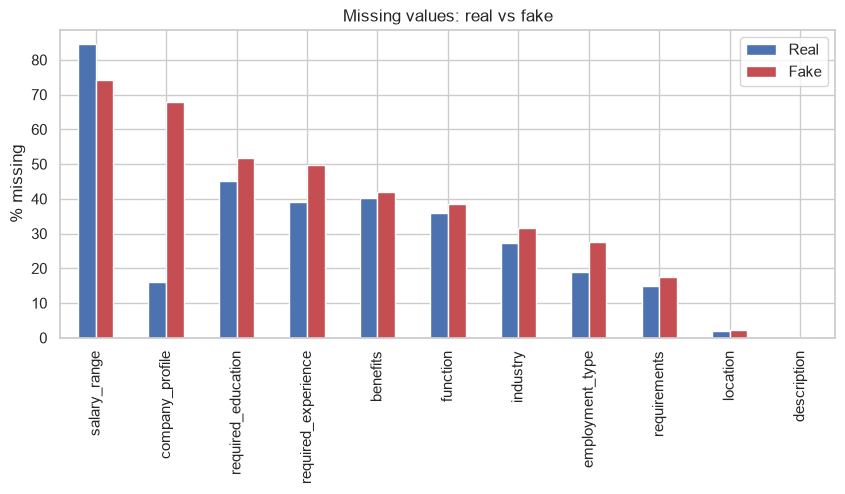

In [5]:
miss = pd.DataFrame({"Real": dedup[dedup.fraudulent==0].isna().mean()*100, "Fake": dedup[dedup.fraudulent==1].isna().mean()*100}).drop("fraudulent")
miss = miss[(miss.sum(axis=1) > 0)].sort_values("Fake", ascending=False)
miss.plot.bar(figsize=(10,4), color=["#4C72B0","#C44E52"]); plt.ylabel("% missing"); plt.title("Missing values: real vs fake")
save("02_missing_by_class.png")

**Finding:** fake ads skip company profile and other fields far more often than real ads.

has_company_logo
0    15.8
1     2.0
Name: fraudulent, dtype: float64


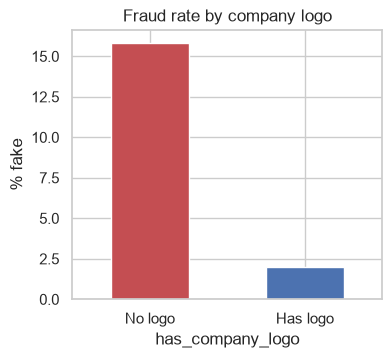

In [6]:
g = df.groupby("has_company_logo").fraudulent.mean().mul(100)
print(g.round(1))
ax = g.rename({0:"No logo",1:"Has logo"}).plot.bar(rot=0, color=["#C44E52","#4C72B0"], figsize=(4,3.5)); ax.set_ylabel("% fake"); ax.set_title("Fraud rate by company logo")
save("03_logo_fraud.png")

**Finding:** ads without a company logo are fake far more often (roughly 16% vs 2%).

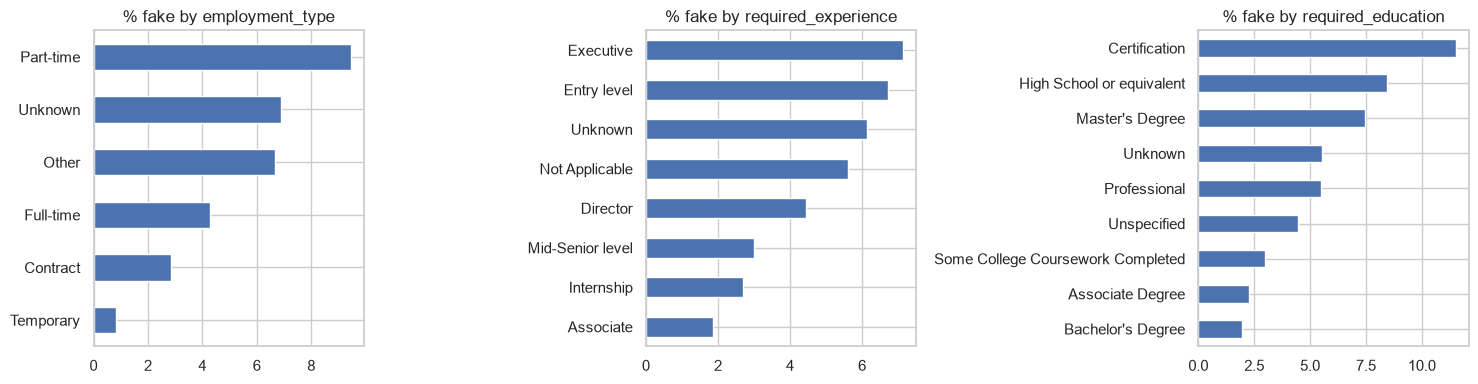

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(15,4))
for ax, c in zip(axs, ["employment_type","required_experience","required_education"]):
    df.groupby(c).fraudulent.agg(["mean","size"]).query("size>=50")["mean"].mul(100).sort_values().plot.barh(ax=ax); ax.set_title(f"% fake by {c}"); ax.set_ylabel("")
plt.tight_layout(); save("04_fraud_by_category.png")

**Finding:** fraud rate varies a lot by employment type and the experience/education requested; "Unknown" (blank) is itself a strong signal.

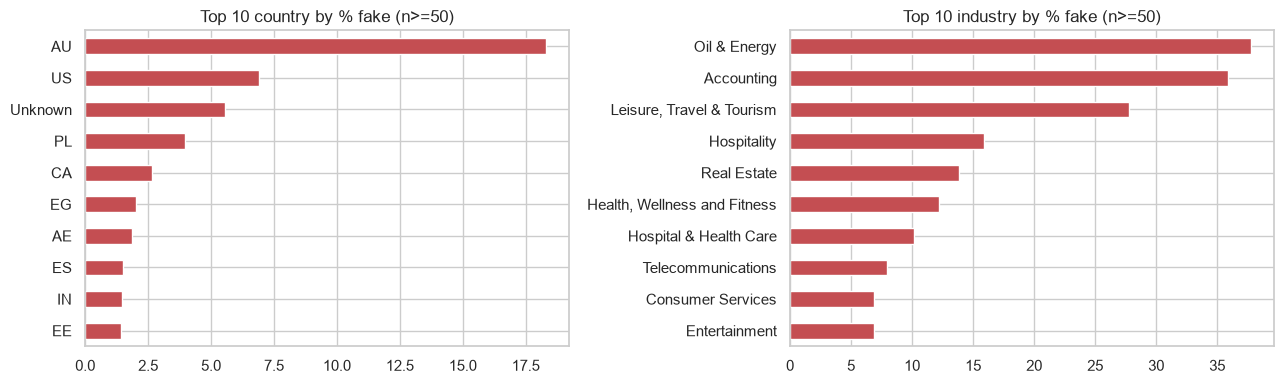

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(13,4))
for ax, c in zip(axs, ["country","industry"]):
    df.groupby(c).fraudulent.agg(["mean","size"]).query("size>=50")["mean"].mul(100).sort_values().tail(10).plot.barh(ax=ax, color="#C44E52"); ax.set_title(f"Top 10 {c} by % fake (n>=50)"); ax.set_ylabel("")
plt.tight_layout(); save("05_top_country_industry.png")

**Finding:** fraud is concentrated in a few countries and industries (groups with fewer than 50 ads excluded).

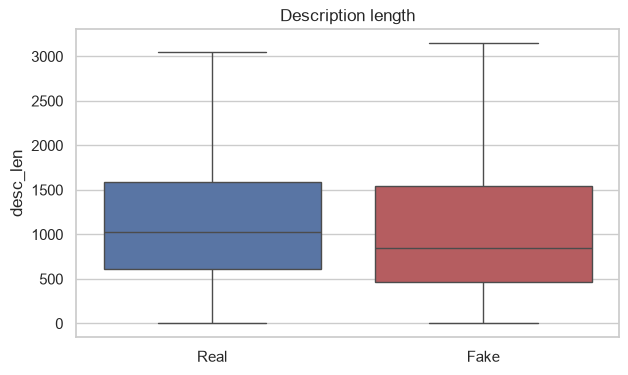

In [9]:
fig, ax = plt.subplots(figsize=(7,4))
sns.boxplot(data=df.assign(label=df.fraudulent.map({0:"Real",1:"Fake"})), x="label", y="desc_len", ax=ax, showfliers=False, palette=["#4C72B0","#C44E52"])
ax.set_title("Description length"); ax.set_xlabel(""); save("06_desc_length.png")

**Finding:** description length differs between real and fake ads, but with a lot of overlap, so it is a weak signal on its own.

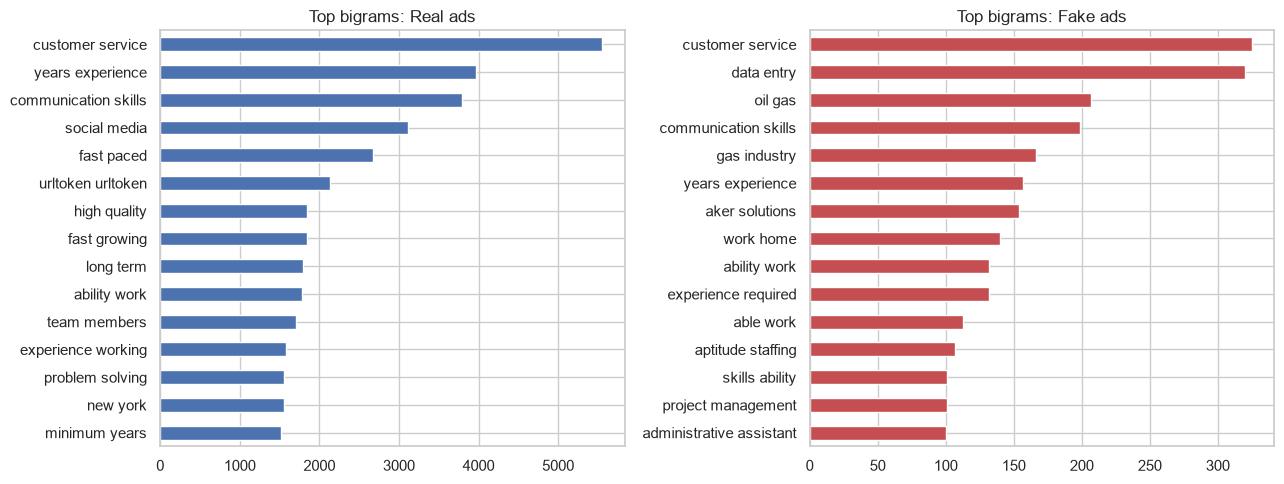

In [10]:
from sklearn.feature_extraction.text import CountVectorizer
fig, axs = plt.subplots(1, 2, figsize=(13,5))
for ax, (lab, name, col) in zip(axs, [(0,"Real","#4C72B0"),(1,"Fake","#C44E52")]):
    cv = CountVectorizer(ngram_range=(2,2), stop_words="english", max_features=15)
    m = cv.fit_transform(df.loc[df.fraudulent==lab,"text"])
    s = pd.Series(np.asarray(m.sum(0)).ravel(), index=cv.get_feature_names_out()).sort_values()
    s.plot.barh(ax=ax, color=col); ax.set_title(f"Top bigrams: {name} ads")
plt.tight_layout(); save("07_top_bigrams.png")

**Finding:** real ads talk about experience, teams and clients; fake ads lean on links, earning money and working from home.

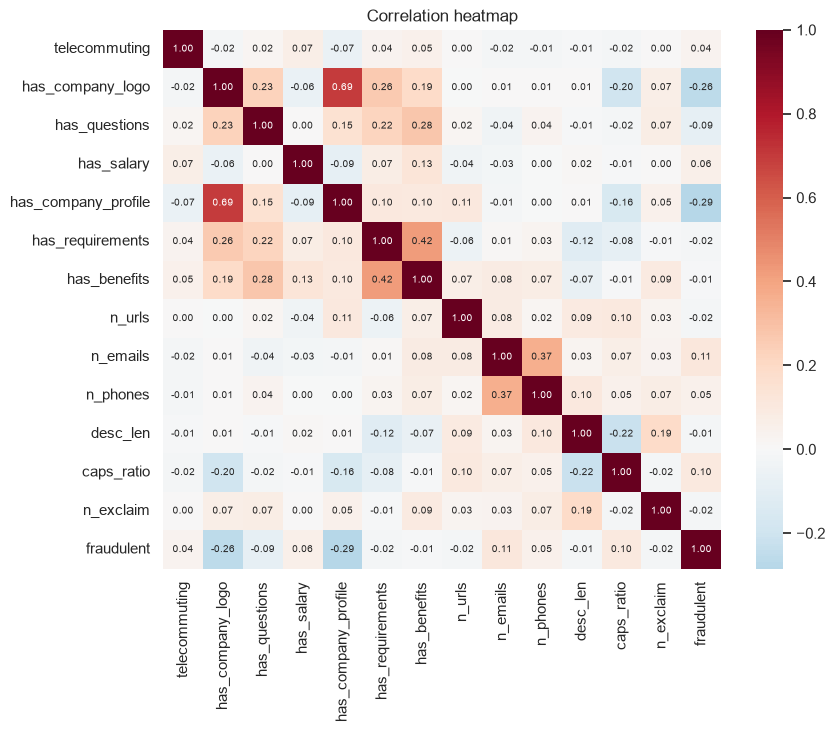

In [11]:
num = ["telecommuting","has_company_logo","has_questions","has_salary","has_company_profile","has_requirements","has_benefits","n_urls","n_emails","n_phones","desc_len","caps_ratio","n_exclaim","fraudulent"]
plt.figure(figsize=(9,7)); sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size":7}); plt.title("Correlation heatmap")
save("08_correlation.png")

**Finding:** `has_company_logo` and `has_company_profile` are the most negatively correlated with fraud; no single feature is strong enough alone, which motivates an ensemble.